# XGBoost Optimization & Model Explainability
---
**Objective:**
Following the architectural decisions made during the benchmarking phase, this notebook focuses entirely on optimizing the **XGBoost** model. As established, XGBoost demonstrated superior performance on the raw, unscaled dataset by naturally exploiting the extreme variance in transaction amounts and orthogonal PCA features.

**Optimization Roadmap:**
1. **Hyperparameter Tuning (Optuna):** Search for the optimal tree architecture and learning rates to surpass our baseline F1-Score of 0.8538.
2. **Threshold Calibration (Threshold Moving):** Move away from the default 0.5 decision boundary to find a custom probability threshold that maximizes Precision without sacrificing Recall.
3. **Decision Transparency (SHAP):** Utilize Shapley Additive Explanations (TreeExplainer) to demystify the model's internal logic and understand which features drive the identification of fraudulent patterns.

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import classification_report, f1_score, precision_score, recall_score, average_precision_score, confusion_matrix, precision_recall_curve
import xgboost as xgb
import warnings
import time
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
import shap

In [2]:
df=pd.read_csv("creditcard_benchmark.csv")
print(df.head()) #Confirming dataset loaded correctly

   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V27       V28 

In [3]:
X = df.drop('Class', axis=1)
y = df['Class']

X_train_raw, X_test_raw, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scale_pos_weight_value = (y_train == 0).sum() / (y_train == 1).sum()

### Hyperparameter Tuning Strategy
To systematically explore the hyperparameter space, we employ the **Optuna** optimization framework. While tree-specific parameters (depth, learning rate, regularization) will be optimized dynamically, three critical architectural constraints are hardcoded to handle the extreme class imbalance:

1. **`objective = 'binary:logistic'`**: Forces the model to apply a sigmoid function to its raw output, generating a calibrated probability (0.0 to 1.0) rather than log-odds. This is strictly required for downstream Threshold Moving and Ensemble blending.
2. **`eval_metric = 'aucpr'`**: Precision-Recall AUC is utilized as the evaluation metric instead of standard ROC-AUC or Accuracy. AUCPR completely ignores the massive True Negative class, forcing Optuna to select hyperparameter sets that excel specifically at minority class detection across all possible probability thresholds.
3. **`scale_pos_weight`**: We dynamically calculate the exact ratio of legitimate to fraudulent transactions. This mathematical multiplier acts as a severe penalty during training, forcing the algorithm to treat a single misclassified fraud as heavily as thousands of misclassified legitimate transactions, effectively neutralizing the 99.8% class imbalance.

In [6]:
def objective(trial):
    param = {
        'objective': 'binary:logistic',
        'eval_metric': 'aucpr',
        'scale_pos_weight': scale_pos_weight_value,
        'n_estimators': trial.suggest_int('n_estimators', 100, 500),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 9),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'gamma': trial.suggest_float('gamma', 0, 5),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
        'random_state': 42,
        'n_jobs': -1
    }
    
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    pr_auc_scores = []
    
    for train_idx, val_idx in cv.split(X_train_raw, y_train):
        X_tr, X_val = X_train_raw.iloc[train_idx], X_train_raw.iloc[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
        
        model = xgb.XGBClassifier(**param)
        model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)
        
        preds = model.predict_proba(X_val)[:, 1]
        score = average_precision_score(y_val, preds)
        pr_auc_scores.append(score)
        
    return np.mean(pr_auc_scores)

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=100)

print("Best parameters:")
print(study.best_params)
print(f"Highest PR-AUC: {study.best_value:.4f}")

[I 2026-09-04 18:22:56,996] A new study created in memory with name: no-name-c23192d0-698c-4014-87d2-0e1558989bc3
[I 2026-09-04 18:23:08,565] Trial 0 finished with value: 0.8303765655170003 and parameters: {'n_estimators': 356, 'learning_rate': 0.0670416237658563, 'max_depth': 3, 'min_child_weight': 5, 'subsample': 0.868560441770223, 'colsample_bytree': 0.7545472043399659, 'gamma': 1.3885221567952666, 'reg_alpha': 0.0011258335612048611, 'reg_lambda': 0.010976628124819804}. Best is trial 0 with value: 0.8303765655170003.
[I 2026-09-04 18:23:22,673] Trial 1 finished with value: 0.8482064426544575 and parameters: {'n_estimators': 485, 'learning_rate': 0.10095710562998331, 'max_depth': 8, 'min_child_weight': 1, 'subsample': 0.9482954308877612, 'colsample_bytree': 0.6636694108529045, 'gamma': 1.448835719422642, 'reg_alpha': 0.2079643079416712, 'reg_lambda': 0.0013040985223147991}. Best is trial 1 with value: 0.8482064426544575.
[I 2026-09-04 18:23:36,258] Trial 2 finished with value: 0.8497

Best parameters:
{'n_estimators': 305, 'learning_rate': 0.10043085490292052, 'max_depth': 9, 'min_child_weight': 6, 'subsample': 0.6778959535949641, 'colsample_bytree': 0.8726874144532479, 'gamma': 0.9014231377051063, 'reg_alpha': 0.005303631747420247, 'reg_lambda': 0.022530748127275284}
Highest PR-AUC: 0.8566


### Probability Threshold Calibration (Threshold Moving)
Standard classification models default to a 0.5 probability decision boundary. However, in fraud detection, this mathematically rigid default is rarely optimal for the business bottom line. 

By extracting the raw probabilities (`predict_proba`) and testing them against a sliding threshold scale, we can map the exact Precision-Recall trade-off. Our goal is to identify the optimal "sweet spot" (maximized via F1-Score) where we catch the maximum number of true frauds while strictly minimizing the operational cost of False Positives (blocking legitimate customers' cards).

In [4]:
best_params = {
    'objective': 'binary:logistic',
    'eval_metric': 'aucpr',
    'scale_pos_weight': scale_pos_weight_value,
    'n_estimators': 305,
    'learning_rate': 0.10043085490292052,
    'max_depth': 9,
    'min_child_weight': 6,
    'subsample': 0.6778959535949641,
    'colsample_bytree': 0.8726874144532479,
    'gamma': 0.9014231377051063,
    'reg_alpha': 0.005303631747420247,
    'reg_lambda': 0.022530748127275284,
    'random_state': 42,
    'n_jobs': -1
}

final_xgb= xgb.XGBClassifier(**best_params)
final_xgb.fit(X_train_raw, y_train)

proba_test = final_xgb.predict_proba(X_test_raw)[:,1]

thresholds = np.arange(0.1, 0.96, 0.01)
results = []

for t in thresholds:
    y_pred_t = (proba_test >= t).astype(int)

    cm = confusion_matrix(y_test, y_pred_t)
    tn, fp, fn, tp = cm.ravel()

    f1 = f1_score(y_test, y_pred_t)
    recall = recall_score(y_test, y_pred_t)
    precision = precision_score(y_test, y_pred_t)

    results.append({
        'Threshold': round(t, 2),
        'F1-Score': round(f1, 4),
        'Recall': round(recall, 4),
        'Precision': round(precision, 4),
        'TP (Caught)': tp,
        'FP (False Alarm)': fp
    })

df_thresholds = pd.DataFrame(results)
print("Probability threshold analysis results:")
display(df_thresholds)

best_row = df_thresholds.loc[df_thresholds['F1-Score'].idxmax()]
print("\n Optimal threshold based on F1-Score:")
print(f"Threshold: {best_row['Threshold']}")
print(f"Best F1-Score: {best_row['F1-Score']}")
print(f"Optimal threshold's Recall: {best_row['Recall']}")
print(f"Optimal threshold's Precision: {best_row['Precision']}")
print(f"Optimal threshold's Caught Frauds: {best_row['TP (Caught)']} / False Alarms: {best_row['FP (False Alarm)']}")

Probability threshold analysis results:


,Threshold,F1-Score,Recall,Precision,TP (Caught),FP (False Alarm)
0,0.10,0.7958,0.8000,0.7917,76,20
1,0.11,0.7958,0.8000,0.7917,76,20
2,0.12,0.7958,0.8000,0.7917,76,20
3,0.13,0.8000,0.8000,0.8000,76,19
4,0.14,0.8085,0.8000,0.8172,76,17
...,...,...,...,...,...,...
81,0.91,0.8571,0.7579,0.9863,72,1
82,0.92,0.8571,0.7579,0.9863,72,1
83,0.93,0.8571,0.7579,0.9863,72,1
84,0.94,0.8503,0.7474,0.9861,71,1



 Optimal threshold based on F1-Score:
Threshold: 0.54
Best F1-Score: 0.8671
Optimal threshold's Recall: 0.7895
Optimal threshold's Precision: 0.9615
Optimal threshold's Caught Frauds: 75.0 / False Alarms: 3.0


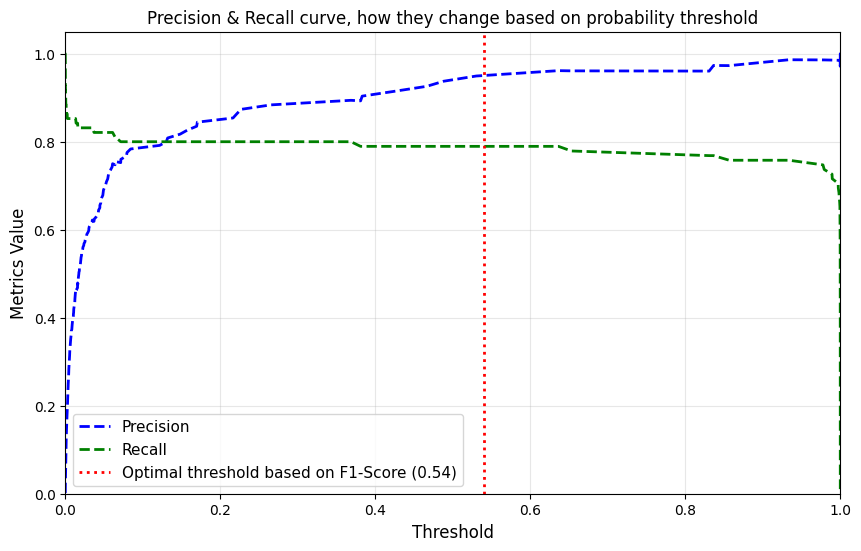

In [5]:
precisions, recalls, thresholds_pr = precision_recall_curve(y_test, proba_test)

plt.figure(figsize=(10,6))

plt.plot(thresholds_pr, precisions[:-1], "b--", label='Precision', linewidth = 2)
plt.plot(thresholds_pr, recalls[:-1], "g--", label='Recall', linewidth=2)

optimal_threshold = best_row['Threshold']
plt.axvline(x=optimal_threshold, color = 'r', linestyle=":", linewidth = 2, label = f'Optimal threshold based on F1-Score ({optimal_threshold})')

plt.xlabel("Threshold", fontsize=12)
plt.ylabel("Metrics Value", fontsize=12)
plt.title("Precision & Recall curve, how they change based on probability threshold")
plt.legend(loc="lower left", fontsize= 11)
plt.grid(True, alpha = 0.3)
plt.xlim([0, 1.0])
plt.ylim([0, 1.05])

plt.show()

**Strategic Threshold Adjustment: Moving to 0.60**
While the strict mathematical optimum for the F1-Score is calculated at a probability threshold of 0.54, visual inspection of the Precision-Recall curve reveals a clear business opportunity. By manually shifting the decision boundary to 0.60:
*   **Recall Stability:** The Recall curve rests on a completely flat plateau. We do not sacrifice the detection of any true frauds.
*   **UX Protection & Concept Drift:** In a live production environment, transaction patterns continuously evolve. Establishing this 0.60 "safety buffer" protects the system against natural data drift. It ensures that if future legitimate transactions begin to score slightly higher due to changing customer behaviors, they will not cross the decision boundary, thus preventing unnecessary card blocks and customer frustration.

*Please note, threshold moved to 0.60 won't be validated in this notebook.*



### Model Explainability (SHAP Analysis)
To conclude the evaluation of the standalone XGBoost architecture, we will calculate SHAP (SHapley Additive exPlanations) values. This allows us to transition from evaluating *how well* the model performs to understanding *why* it makes specific predictions. We will analyze global feature impacts and perform a local, deep-dive inspection of a single correctly caught fraudulent transaction (True Positive) to validate the model's underlying logic.


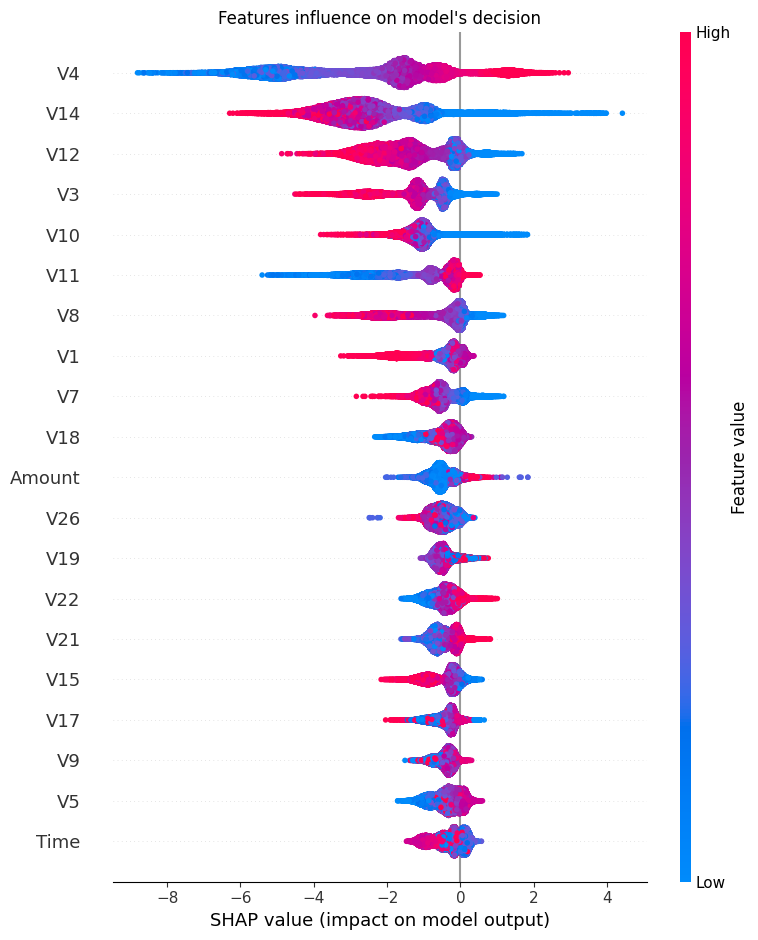

In [6]:
explainer = shap.TreeExplainer(final_xgb)
shap_values = explainer(X_test_raw)

plt.figure(figsize=(12,8))
shap.summary_plot(shap_values, X_test_raw, show=False, plot_type='dot')
plt.title("Features influence on model's decision")
plt.tight_layout()
plt.show()                  

### Global Feature Importance (SHAP Summary Plot)
The SHAP summary plot decodes the overarching 'reasoning' behind the XGBoost model's predictions, revealing which features drive the decision boundary.

**Key SHAP Insights:**
* **The Primary Gatekeeper (`V4`):** `V4` provides the highest information gain, acting almost as a standalone legitimacy filter. A distinct, long tail of low values (blue dots) pushes the SHAP value down to -8, strongly indicating a safe transaction. High values (red dots) push the prediction toward fraud. This perfectly validates our initial EDA correlation matrix, which flagged `V4` as the top positively correlated feature (0.129).
* **The Fraud Triggers (`V14`, `V12`, `V10`):** These features exhibit an inverse relationship compared to `V4`. Extremely low feature values (blue dots) strongly drive the prediction toward fraud (SHAP values up to +4). Again, this beautifully aligns with our EDA phase, where `V14`, `V12`, and `V10` were identified as the strongest negatively correlated features. 
* **The Contextual Nature of `Amount`:** The non-anonymized `Amount` feature ranks 11th in importance, which perfectly aligns with our initial EDA where it exhibited an extremely weak linear correlation with the target class. Most of its SHAP values are clustered tightly around zero impact. While red dots (higher values) appear slightly right-skewed toward fraud, we must consider the dataset's distribution: the median transaction is ~22 USD, while the mean is ~88 USD. Therefore, these "high" red values represent moderately elevated amounts, not the 25,000 USD extreme outliers. A massive legitimate transaction outlier is simply neutralized if `V4` strongly signals legitimacy. This confirms that `Amount` holds very little standalone predictive power and acts entirely as a contextual modifier for the dominant PCA features.
* **The Irrelevance of Raw `Time`:** The raw `Time` feature (seconds elapsed) took absolute last place, providing negligible predictive value for XGBoost. This exposes a fundamental limitation of tree-based models: while robust to unscaled data, decision trees are mathematically blind to periodicity. They treat time as a monotonic linear counter rather than a repeating cycle (e.g., matching 02:00 AM on Day 1 with 02:00 AM on Day 2). This validates our choice to use cyclical trigonometric encoding (`Hour_sin` / `Hour_cos`) in the engineered dataset, allowing the Random Forest model to easily split on specific times of the day, while simultaneously satisfying the spatial distance requirements of SMOTEENN.

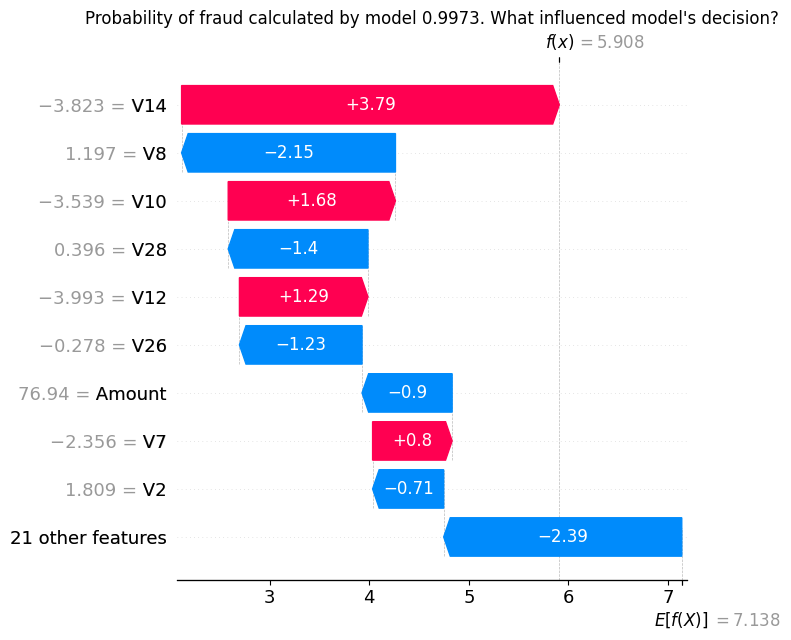

In [9]:
fraud_indices = np.where((y_test ==1) & (proba_test >=0.54))[0]
if len(fraud_indices) > 0:
    example_idx = fraud_indices[0]

    plt.figure(figsize=(10,6))
    shap.plots.waterfall(shap_values[example_idx], max_display=10, show=False)

    plt.title(f"Probability of fraud calculated by model {proba_test[example_idx]:.4f}. What influenced model's decision?")
    plt.tight_layout()
    plt.show()

### Local Interpretability: Deep-Dive into a True Positive (Fraud)
To validate our global findings, we inspect a specific, correctly identified fraudulent transaction (True Positive) using a SHAP waterfall plot. The model assigned this transaction a **99.73% probability of fraud**.

**Key Local Insights:**
* **The Power of `scale_pos_weight`:** The analysis starts at the bottom with an expected base value $E[f(X)]$ of **+7.138**. This exceptionally high starting point is the direct mathematical result of our `scale_pos_weight` hyperparameter. Because the model is strictly penalized for missing frauds, its default stance assumes extreme risk before evaluating any individual features.
* **The "Legitimate" Disguise:** Visually, the majority of the features actually pull the prediction *down* towards legitimacy (blue bars). A combination of 21 background features reduces the score by 2.39. Furthermore, standard features like `V8` (reducing the score by 2.15) and even the `Amount` of 76.94 USD (reducing the score by 0.9) suggest this is a perfectly normal, everyday transaction.
* **The Multivariate Anomaly:** The fraud is successfully caught almost entirely due to a concentrated anomaly in just four features: `V14`, `V10`, `V12`, and `V7`. Specifically, the extremely low value of `V14` (-3.823) alone adds +3.79 to the fraud score, overpowering the disguise.

**Algorithmic Superiority:**
This case perfectly demonstrates the advantage of machine learning over legacy rule-based systems. A hardcoded rules engine would likely approve this transaction, completely deceived by the normal purchase amount and the overwhelming number of benign data points. The XGBoost model, however, correctly isolates the hidden multivariate anomaly in the PCA features, preventing the fraud from slipping through.